# Notebook 10 — Diminishing-Returns Analysis

**Hyperparameter-optimisation experiment · Soccer Event Transformer · Track A model family**

| Item | Content |
|---|---|
| **Question** | Does validation NLL keep improving as model capacity and training cost increase, or does it level off, and if it levels off, where? |
| **Purpose of this notebook** | Relate parameter count, depth, head count, context length, training time and peak GPU memory to validation NLL for the capacity-sweep configurations, and test whether the measurements support a distinct saturation point. |
| **Inputs** | `results/08_capacity_runs.csv` (46 runs: 23 architectures × seeds 0 and 1, all at the Track A training setting: learning rate 3e-4, weight decay 0.1), `results/08_profile.csv` (measured peak GPU memory and step time per architecture), `results/09_hyperparameter_runs.csv` (36 training-hyperparameter search runs; loaded and counted, see Section 1). |
| **Training performed** | None. This notebook only reads result files. |
| **Test data** | Not used. |
| **Outputs** | `results/10_frontier.csv`, `results/10_marginal_returns.csv`, `results/10_depth_steps.csv`, `results/10_elbow_report.json`, `results/10_summary.json`, figures in `figures/`. |


In [ ]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every notebook of this experiment)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import math
import copy
import hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Existing Track A outputs.
EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"

OPT_DIR = EXISTING_DIR / "experiments" / "hyperparameter_optimisation"
RUNS_DIR = OPT_DIR / "runs"
RESULTS_DIR = OPT_DIR / "results"
FIGURES_DIR = OPT_DIR / "figures"
CONFIG_DIR = OPT_DIR / "config"
MANIFEST_DIR = OPT_DIR / "manifests"
LOG_DIR = OPT_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Track A project (read-only):", EXISTING_DIR)
print("Experiment outputs:", OPT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True | RUN_MODE: full
Track A project (read-only): /content/drive/MyDrive/soccer_mi/track_a
Experiment outputs: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib

import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

with open(EXISTING_FROZEN_CONFIG) as handle:
    TRACK_A_FROZEN = json.load(handle)

ENCODING = TRACK_A_FROZEN["encoding"]
POSSESSION_FEATURES = TRACK_A_FROZEN["possession_features"]
STRIDE = TRACK_A_FROZEN["stride"]

BASE_LAYERS = TRACK_A_FROZEN["model"]["n_layers"]
BASE_HEADS = TRACK_A_FROZEN["model"]["n_heads"]
BASE_D_MODEL = TRACK_A_FROZEN["model"]["d_model"]
BASE_D_FF = TRACK_A_FROZEN["model"]["d_ff"]
BASE_CONTEXT = TRACK_A_FROZEN["context_length"]
BASE_LR = TRACK_A_FROZEN["training"]["learning_rate"]
BASE_WD = TRACK_A_FROZEN["training"]["weight_decay"]
EPOCH_BUDGET = TRACK_A_FROZEN["training"]["max_epochs"]

print("Events:", len(events), "| device:", DEVICE)
print("Track A reference configuration:",
      f"L{BASE_LAYERS} H{BASE_HEADS} d_model {BASE_D_MODEL} d_ff {BASE_D_FF} K{BASE_CONTEXT}",
      f"| lr {BASE_LR:g} wd {BASE_WD:g} | epoch budget {EPOCH_BUDGET}")

Events: 658905 | device: cuda
Track A reference configuration: L2 H2 d_model 128 d_ff 512 K16 | lr 0.0003 wd 0.1 | epoch budget 30


In [ ]:
# -----------------
# Helper functions
# -----------------

SHORT_NAME = {"batch_size": "bs", "warmup_fraction": "wu"}


def transformer_config(seed, n_layers, n_heads, context_length, d_model=None, d_ff=None,
                       learning_rate=None, weight_decay=None, max_epochs=None):
    """Build a run configuration in exactly the format used by the Track A notebooks."""
    model = {"n_layers": n_layers, "n_heads": n_heads,
             "d_model": BASE_D_MODEL if d_model is None else d_model,
             "d_ff": BASE_D_FF if d_ff is None else d_ff}
    training_settings = {"learning_rate": BASE_LR if learning_rate is None else learning_rate,
                         "weight_decay": BASE_WD if weight_decay is None else weight_decay,
                         "max_epochs": EPOCH_BUDGET if max_epochs is None else max_epochs}
    return {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
            "context_length": context_length, "stride": STRIDE, "seed": seed,
            "model": model, "training": training_settings}


def architecture_label(config):
    """Readable architecture name, e.g. L4-H2-K16-D128-F512."""
    model = config["model"]
    return (f"L{model['n_layers']}-H{model['n_heads']}-K{config['context_length']}"
            f"-D{model['d_model']}-F{model['d_ff']}")


def variant_tag(training_settings):
    """Sub-folder for training settings that training.run_name_for() does not encode.

    run_name_for() encodes the learning rate, weight decay, architecture, context length and
    seed, but not the batch size or the warm-up fraction. To prevent runs that differ only in those
    two settings (batch size or the warm-up fraction) to be written to the same folder.
    """
    parts = []
    for key in ["batch_size", "warmup_fraction"]:
        if key in training_settings and training_settings[key] != training.DEFAULT_TRAINING[key]:
            parts.append(f"{SHORT_NAME[key]}{training_settings[key]:g}")
    return "_".join(parts) if parts else "base"


_BUNDLES = {}


def bundle_for(context_length):
    """Encoded data and evaluation views for one context length (built once, then reused)."""
    if context_length not in _BUNDLES:
        _BUNDLES[context_length] = training.prepare_data(
            events, ARTIFACTS_DIR, ENCODING, POSSESSION_FEATURES, context_length, STRIDE, DEVICE, RUN_MODE)
    return _BUNDLES[context_length]


def parameter_count(config):
    """Total parameters of a configuration, without training it."""
    model = training.build_model(config, bundle_for(config["context_length"])["vocabulary_sizes"])
    return model_module.count_parameters(model)["total"]


def run_one(config, extra_training=None, keep_every_epoch=False, verbose=True):
    """Train one configuration (or reload it if its folder already holds a finished run).

    Returns (run_dir, final_results). Nothing outside RUNS_DIR is written.
    """
    config = copy.deepcopy(config)
    if extra_training:
        config["training"].update(extra_training)
    runs_root = RUNS_DIR / variant_tag(config["training"])
    runs_root.mkdir(parents=True, exist_ok=True)
    result = training.train_run(config, bundle_for(config["context_length"]), runs_root,
                                MANIFEST_PATH, keep_every_epoch=keep_every_epoch, verbose=verbose)
    return runs_root / training.run_name_for(config), result


def result_row(config, run_dir, result, group=""):
    """One flat record per run, holding every quantity the later notebooks need."""
    val = result["val_metrics"]
    training_settings = result["training_settings"]
    return {
        "group": group,
        "architecture": architecture_label(config),
        "n_layers": config["model"]["n_layers"],
        "n_heads": config["model"]["n_heads"],
        "d_head": config["model"]["d_model"] // config["model"]["n_heads"],
        "d_model": config["model"]["d_model"],
        "d_ff": config["model"]["d_ff"],
        "context_length": config["context_length"],
        "learning_rate": training_settings["learning_rate"],
        "weight_decay": training_settings["weight_decay"],
        "batch_size": training_settings["batch_size"],
        "warmup_fraction": training_settings["warmup_fraction"],
        "seed": config["seed"],
        "parameters": result["parameter_counts"]["total"],
        "trainable_parameters": result["parameter_counts"].get("trainable", result["parameter_counts"]["total"]),
        "val_nll": val["nll"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"],
        "val_top3": val["top3_accuracy"],
        "val_top5": val["top5_accuracy"],
        "val_ece": val["ece"],
        "train_nll": result["train_nll"],
        "best_epoch": result["best_epoch"],
        "epochs_run": result["epochs_run"],
        "stopped_early": result["stopped_early"],
        "diverged": result["diverged"],
        "runtime_seconds": result["runtime_seconds"],
        "run_dir": str(run_dir),
        "run_name": result["run_name"],
    }


def append_results(rows, csv_path):
    """Append run records to a CSV, keeping one row per run name and variant folder."""
    table = pd.DataFrame(rows)
    if Path(csv_path).exists():
        table = pd.concat([pd.read_csv(csv_path), table], ignore_index=True)
    table = table.drop_duplicates(subset=["run_dir"], keep="last").reset_index(drop=True)
    table.to_csv(csv_path, index=False)
    return table


def seed_level_to_config_level(table):
    """Average the seed-level records of each configuration into one row per configuration."""
    keys = ["group", "architecture", "n_layers", "n_heads", "d_head", "d_model", "d_ff",
            "context_length", "learning_rate", "weight_decay", "batch_size", "warmup_fraction",
            "parameters"]
    summary = table.groupby(keys, as_index=False, sort=False).agg(
        n_seeds=("seed", "count"),
        val_nll=("val_nll", "mean"),
        val_nll_sd=("val_nll", "std"),
        val_accuracy=("val_accuracy", "mean"),
        val_accuracy_sd=("val_accuracy", "std"),
        val_macro_f1=("val_macro_f1", "mean"),
        val_top3=("val_top3", "mean"),
        val_top5=("val_top5", "mean"),
        val_ece=("val_ece", "mean"),
        train_nll=("train_nll", "mean"),
        best_epoch=("best_epoch", "mean"),
        runtime_seconds=("runtime_seconds", "mean"),
    )
    return summary.sort_values("val_nll").reset_index(drop=True)


def run_dirs_for(table, **conditions):
    """All run directories in a results table that match the given column values."""
    selected = table
    for column, value in conditions.items():
        selected = selected[selected[column] == value]
    return [Path(path) for path in selected["run_dir"]]


print("Helper functions defined.")

Helper functions defined.


## 1. What this notebook does and does not claim

The analysis is descriptive. It plots measured quantities against one another and asks whether the pattern supports a saturation point. No model-selection decision is made here.

**Which runs are analysed.** All figures and fits use the 23 capacity-sweep configurations, which were all trained at the same learning rate (3e-4) and weight decay (0.1). The training-hyperparameter search runs are loaded (82 runs in total across both files) but note replaced, because they differ in training setting as well as architecture and would mix the two effects.

Three points of method, stated before the plots:

**The k-means elbow procedure does not apply.** That procedure plots within-cluster sum of squares against the number of clusters for one dataset and one algorithm, where the vertical quantity is guaranteed to fall monotonically. Neither guarantee holds here: validation NLL is measured on held-out data and can rise with capacity, and neighbouring configurations differ along several axes at once. It is an analysis of the capacity–performance relationship, the k-means elbow algorithm is not applied to another quantity.

**Capacity is not one number.** Depth, context length, head count and width all change what the model can represent, but they change the parameter count very differently: head count does not change it at all, and context length changes it only through the positional embedding table. Each axis is therefore plotted separately as well as against parameter count.

**The reference scale for "negligible" is measured.** A gain can only be called small relative to something. The reference used throughout is the **median seed SD** of validation NLL across the 23 capacity-sweep configurations (each SD computed from seeds 0 and 1). A gain smaller than that cannot be distinguished from the effect of changing the seed.

**RESULT.** The median seed SD is 0.0012 nats. This is the reference scale for the rest of the notebook. With two seeds per configuration, each individual SD is itself a rough estimate.

In [ ]:
CAPACITY_RUNS_CSV = RESULTS_DIR / "08_capacity_runs.csv"
PROFILE_CSV = RESULTS_DIR / "08_profile.csv"
HYPERPARAMETER_RUNS_CSV = RESULTS_DIR / "09_hyperparameter_runs.csv"
for required in [CAPACITY_RUNS_CSV, PROFILE_CSV]:
    if not required.exists():
        raise RuntimeError(f"BLOCKED: {required.name} is missing. Run notebook 08 first.")

capacity_table = pd.read_csv(CAPACITY_RUNS_CSV)
profile_table = pd.read_csv(PROFILE_CSV)
if HYPERPARAMETER_RUNS_CSV.exists():
    search_table = pd.read_csv(HYPERPARAMETER_RUNS_CSV)
else:
    search_table = pd.DataFrame(columns=capacity_table.columns)
    print("Notebook 09 results not found; the analysis uses the capacity sweep only.")

all_runs = pd.concat([capacity_table, search_table], ignore_index=True)
all_runs = all_runs[~all_runs["diverged"]].reset_index(drop=True)

# The capacity analysis uses only runs at the Track A training hyperparameters, so that differences
# between architectures are not confounded with differences in learning rate or weight decay.
capacity_only = capacity_table[(~capacity_table["diverged"])
                               & (capacity_table["learning_rate"] == BASE_LR)
                               & (capacity_table["weight_decay"] == BASE_WD)]
capacity_summary = seed_level_to_config_level(capacity_only)
capacity_summary = capacity_summary.merge(
    profile_table[["architecture", "peak_gpu_memory_mb", "mean_step_seconds"]].drop_duplicates("architecture"),
    on="architecture", how="left")

SEED_NOISE = float(capacity_summary["val_nll_sd"].median(skipna=True))
print(f"Configurations in the capacity analysis: {len(capacity_summary)}")
print(f"Runs in the cost analysis (capacity sweep + search): {len(all_runs)}")
print(f"Median seed standard deviation of validation NLL: {SEED_NOISE:.4f} nats")
print("This value is the reference scale used throughout the notebook.")

Configurations in the capacity analysis: 23
Runs in the cost analysis (capacity sweep + search): 82
Median seed standard deviation of validation NLL: 0.0012 nats
This value is the reference scale used throughout the notebook.


## 2. Parameter count against validation performance

The first two plots put every configuration on one axis: parameter count against validation NLL, and against validation accuracy. The **frontier** — the lowest validation NLL reached at or below each parameter count, walking from the smallest model upwards — is drawn as a line, because a diminishing-returns statement is about that envelope, not about the cloud of points.

**RESULT.** Six configurations lie on the frontier: L2-H2-K8 (0.9077), L2-H2-K16 (0.9064), L4-H2-K8 (0.9041), L4-H2-K16 (0.9027), L6-H1-K16 (0.9026) and L6-H2-K16 (0.9020). All use d_model 128 and d_ff 512; none has K above 16.

In [ ]:
def pareto_frontier(table, x_column="parameters", y_column="val_nll"):
    # Best (lowest) y achieved at or below each x, from the smallest model upwards.
    ordered = table.sort_values(x_column).reset_index(drop=True)
    keep = []
    best_so_far = np.inf
    for position, row in ordered.iterrows():
        if row[y_column] < best_so_far:
            best_so_far = row[y_column]
            keep.append(position)
    return ordered.loc[keep].reset_index(drop=True)


frontier = pareto_frontier(capacity_summary)
frontier.to_csv(RESULTS_DIR / "10_frontier.csv", index=False)
print("Configurations on the parameter/NLL frontier:")
print(frontier[["architecture", "parameters", "val_nll", "val_nll_sd", "val_accuracy",
                "runtime_seconds"]].round(4).to_string(index=False))

Configurations on the parameter/NLL frontier:
       architecture  parameters  val_nll  val_nll_sd  val_accuracy  runtime_seconds
 L2-H2-K8-D128-F512      513551   0.9077      0.0008        0.6189          72.6684
L2-H2-K16-D128-F512      514575   0.9064      0.0008        0.6218          67.1479
 L4-H2-K8-D128-F512      910095   0.9041      0.0015        0.6213         130.7011
L4-H2-K16-D128-F512      911119   0.9027      0.0014        0.6227         105.9108
L6-H1-K16-D128-F512     1307663   0.9026      0.0001        0.6247         140.2174
L6-H2-K16-D128-F512     1307663   0.9020      0.0020        0.6230         139.6421


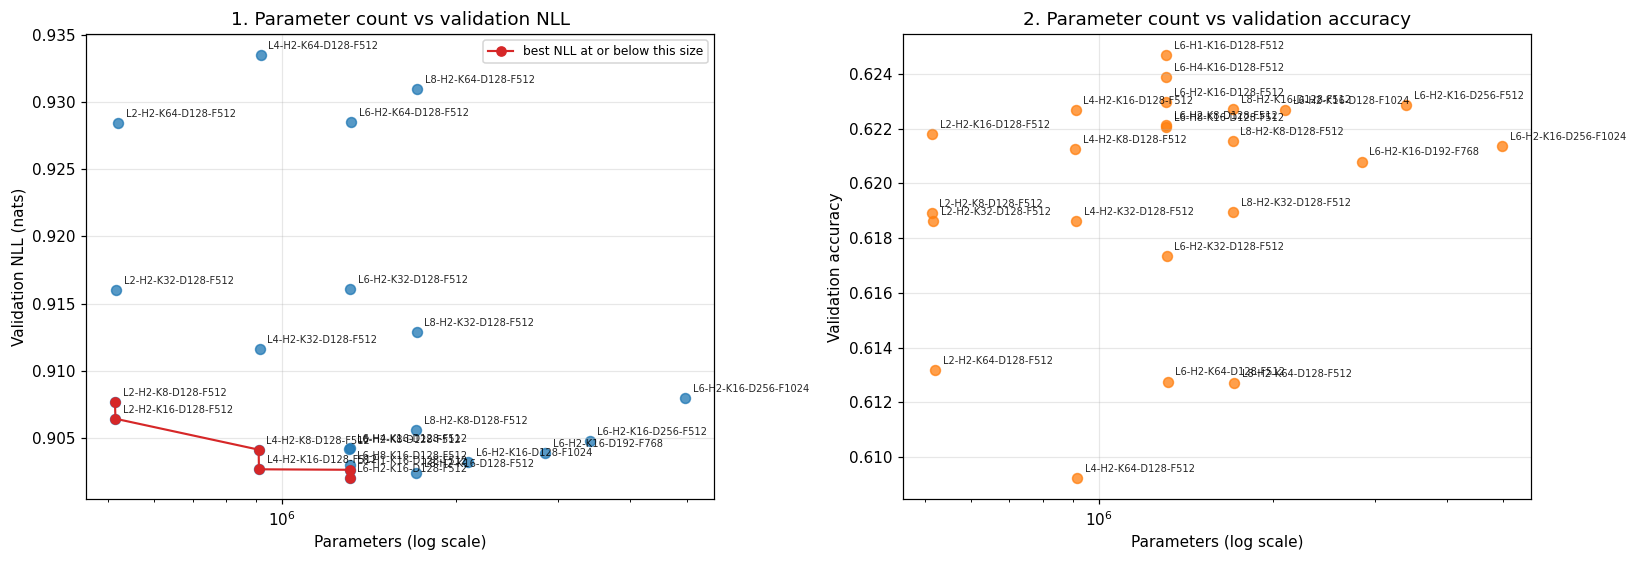

In [ ]:
def annotate_points(ax, table, x_column, y_column, every=1):
    for position, (_, row) in enumerate(table.iterrows()):
        if position % every == 0:
            ax.annotate(row["architecture"], (row[x_column], row[y_column]),
                        textcoords="offset points", xytext=(5, 4), fontsize=6.5, alpha=0.85)


fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].scatter(capacity_summary["parameters"], capacity_summary["val_nll"], s=42, alpha=0.75)
axes[0].plot(frontier["parameters"], frontier["val_nll"], color="tab:red", marker="o",
             linewidth=1.4, label="best NLL at or below this size")
annotate_points(axes[0], capacity_summary, "parameters", "val_nll")
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].set_title("1. Parameter count vs validation NLL")
axes[0].legend(fontsize=8)

axes[1].scatter(capacity_summary["parameters"], capacity_summary["val_accuracy"], s=42,
                alpha=0.75, color="tab:orange")
annotate_points(axes[1], capacity_summary, "parameters", "val_accuracy")
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("2. Parameter count vs validation accuracy")
for ax in axes:
    ax.set_xlabel("Parameters (log scale)")
    ax.set_xscale("log")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_parameters_vs_performance.png", bbox_inches="tight")
plt.show()

**What are we looking at?** Every capacity-sweep configuration (mean over seeds 0 and 1) against its parameter count on a log axis. Left: validation NLL, with the frontier in red. Right: validation accuracy.

**What it shows.** Along the frontier, NLL falls from 0.9077 at 0.51M parameters to 0.9027 at 0.91M, then only to 0.9020 at 1.31M. No configuration above 1.31M parameters (8 layers, or the wider d_model/d_ff variants up to 4.97M) is on the frontier. At a given parameter count the points spread widely in NLL: for example, the four 2-layer configurations range from 0.9064 (K = 16) to 0.9284 (K = 64) at nearly the same size.

**What it means.** Parameter count alone explains little of the variation; the vertical spread is mostly context length (Section 3). Along the frontier the gains become smaller beyond about 0.9M parameters.



## 3. Each capacity axis separately

Parameter count mixes the four capacity axes. The next three panels separate them. Depth and width change the parameter count; head count does not change it; context length changes it only slightly, through the positional embedding table, but changes the attention computation quadratically.

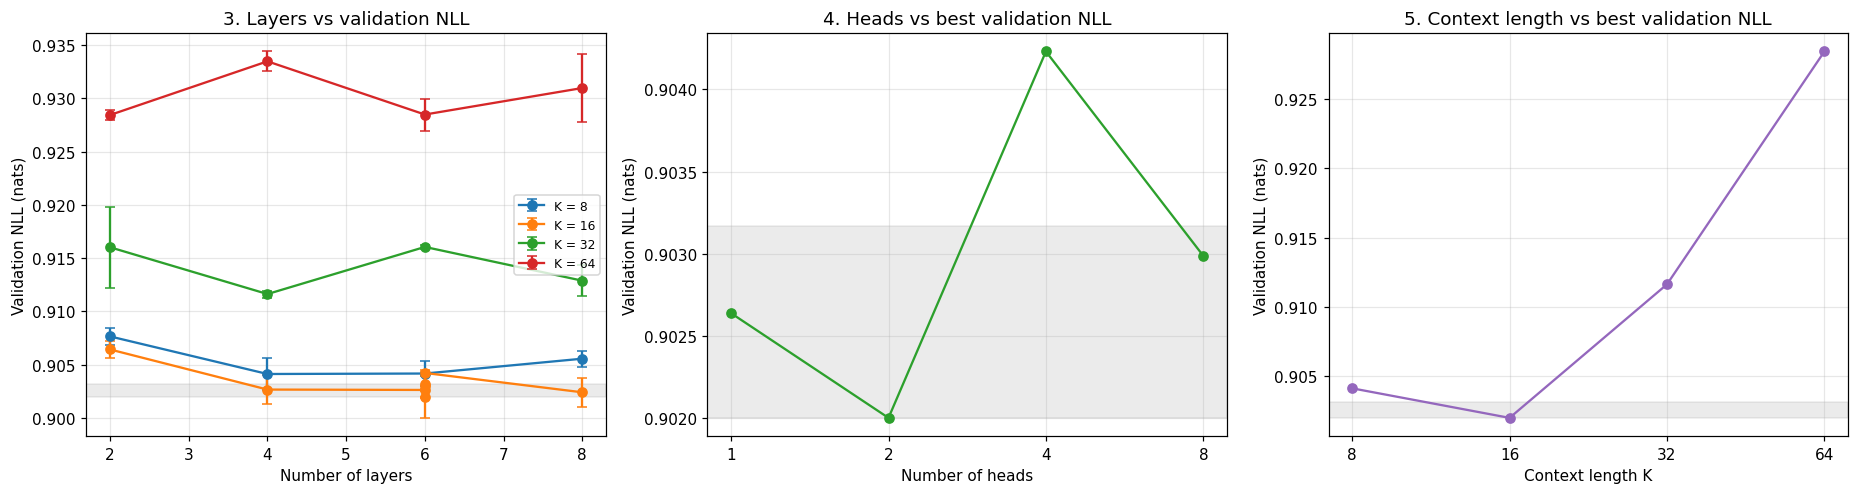

Range of best validation NLL along each axis (nats):
  layers          0.0044
  heads           0.0022
  context length  0.0264
  seed noise      0.0012  (reference scale)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

depth_series = capacity_summary[capacity_summary["d_model"] == BASE_D_MODEL]
for context_length in sorted(depth_series["context_length"].unique()):
    line = depth_series[depth_series["context_length"] == context_length].sort_values("n_layers")
    axes[0].errorbar(line["n_layers"], line["val_nll"], yerr=line["val_nll_sd"].fillna(0),
                     marker="o", capsize=3, label=f"K = {int(context_length)}")
axes[0].set_xlabel("Number of layers")
axes[0].set_title("3. Layers vs validation NLL")
axes[0].legend(fontsize=8)

head_series = capacity_summary.groupby("n_heads", as_index=False).agg(
    val_nll=("val_nll", "min"), val_nll_spread=("val_nll", "std"))
axes[1].plot(head_series["n_heads"], head_series["val_nll"], marker="o", color="tab:green")
axes[1].set_xlabel("Number of heads")
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(head_series["n_heads"])
axes[1].get_xaxis().set_major_formatter(plt.ScalarFormatter())
axes[1].set_title("4. Heads vs best validation NLL")

context_series = capacity_summary.groupby("context_length", as_index=False).agg(val_nll=("val_nll", "min"))
axes[2].plot(context_series["context_length"], context_series["val_nll"], marker="o", color="tab:purple")
axes[2].set_xlabel("Context length K")
axes[2].set_xscale("log", base=2)
axes[2].set_xticks(context_series["context_length"])
axes[2].get_xaxis().set_major_formatter(plt.ScalarFormatter())
axes[2].set_title("5. Context length vs best validation NLL")

for ax in axes:
    ax.set_ylabel("Validation NLL (nats)")
    ax.axhspan(capacity_summary["val_nll"].min(), capacity_summary["val_nll"].min() + SEED_NOISE,
               color="tab:grey", alpha=0.15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_capacity_axes.png", bbox_inches="tight")
plt.show()

print("Range of best validation NLL along each axis (nats):")
print(f"  layers          {depth_series.groupby('n_layers')['val_nll'].min().max() - depth_series.groupby('n_layers')['val_nll'].min().min():.4f}")
print(f"  heads           {head_series['val_nll'].max() - head_series['val_nll'].min():.4f}")
print(f"  context length  {context_series['val_nll'].max() - context_series['val_nll'].min():.4f}")
print(f"  seed noise      {SEED_NOISE:.4f}  (reference scale)")

**What are we looking at?** Panel 3: validation NLL against depth, one line per context length (d_model 128 configurations only), with seed SD as error bars. Panels 4 and 5: the best validation NLL reached at each head count and at each context length. The grey band in every panel starts at the lowest NLL in the sweep and has the height of the median seed SD (0.0012); configurations inside it cannot be told apart by these runs.

**RESULT.** Range of the best validation NLL along each axis: layers 0.0044 nats, heads 0.0022, context length 0.0264. Median seed SD: 0.0012.

**INTERPRETATION.** Context length has by far the largest effect in this sweep, driven by the rise in NLL at K = 32 and K = 64; its range is many times the seed SD. Depth has a moderate effect, a few times the seed SD, coming mainly from the step from 2 to 4 layers. The head-count range is of the same order as the seed SD and is not distinguishable from seed noise with two seeds.

**What we cannot conclude.** These ranges are differences between two-seed means, taken as the best value per axis; they are descriptive and not a test. They also depend on the grid: context length looks important partly because the grid includes K = 64.

## 4. Training cost against validation performance

Cost is measured two ways: wall-clock training time per run, which is what limits a Colab session, and peak GPU memory during a training step, which limits what can be trained at all. Wall-clock time depends on the hardware as well as the model, so it is comparable only within this experiment, where every run used the same GPU type (Tesla T4).

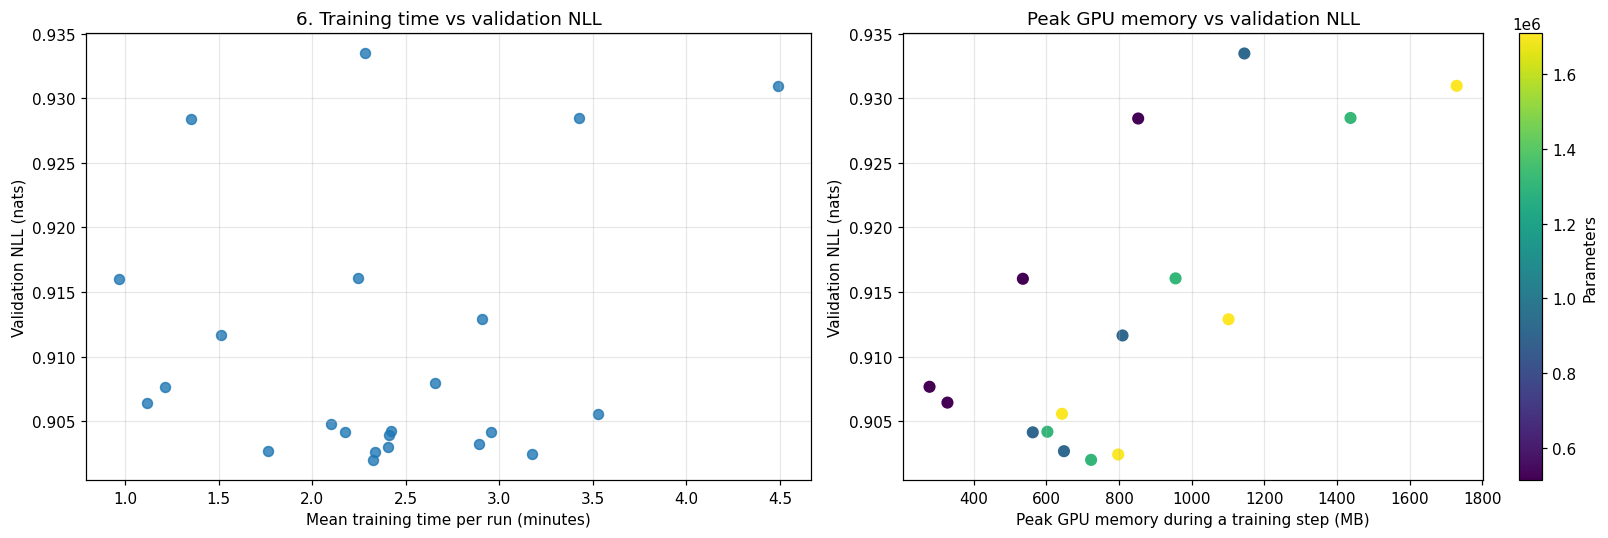

Cheapest configuration : L2-H2-K32-D128-F512, 1.0 min, val NLL 0.9160
Best configuration     : L6-H2-K16-D128-F512, 2.3 min, val NLL 0.9020
Extra time for the gain: 1.4 min for +0.0140 nats


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.0))

axes[0].scatter(capacity_summary["runtime_seconds"] / 60, capacity_summary["val_nll"], s=42, alpha=0.8)
annotate_points(axes[0], capacity_summary, "runtime_seconds", "val_nll")
axes[0].set_xlabel("Mean training time per run (minutes)")
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].set_title("6. Training time vs validation NLL")

with_memory = capacity_summary.dropna(subset=["peak_gpu_memory_mb"])
if len(with_memory):
    points = axes[1].scatter(with_memory["peak_gpu_memory_mb"], with_memory["val_nll"],
                             c=with_memory["parameters"], s=48, cmap="viridis")
    fig.colorbar(points, ax=axes[1], label="Parameters")
    axes[1].set_xlabel("Peak GPU memory during a training step (MB)")
    axes[1].set_ylabel("Validation NLL (nats)")
    axes[1].set_title("Peak GPU memory vs validation NLL")
else:
    axes[1].text(0.5, 0.5, "No GPU memory measurements available", ha="center", va="center")
    axes[1].set_axis_off()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_cost_vs_performance.png", bbox_inches="tight")
plt.show()

fastest = capacity_summary.sort_values("runtime_seconds").iloc[0]
best = capacity_summary.iloc[0]
print(f"Cheapest configuration : {fastest['architecture']}, {fastest['runtime_seconds'] / 60:.1f} min, "
      f"val NLL {fastest['val_nll']:.4f}")
print(f"Best configuration     : {best['architecture']}, {best['runtime_seconds'] / 60:.1f} min, "
      f"val NLL {best['val_nll']:.4f}")
print(f"Extra time for the gain: {(best['runtime_seconds'] - fastest['runtime_seconds']) / 60:.1f} min "
      f"for {fastest['val_nll'] - best['val_nll']:+.4f} nats")

**What are we looking at?** Left: validation NLL against mean training time per run, one point per configuration. Right: validation NLL against the measured peak GPU memory of that architecture, coloured by parameter count.

**RESULT.** The fastest configuration to train is L2-H2-K32 (1.0 minute per run, validation NLL 0.9160); the configuration with the lowest NLL is L6-H2-K16 (2.3 minutes, 0.9020). Moving from the first to the second costs 1.4 extra minutes per run for 0.0140 nats.

**INTERPRETATION.** Runtime reflects when early stopping ended each run as well as model size, so the fastest configuration is not simply the smallest one. The memory panel shows that no trained configuration came close to the memory of the T4, so the sweep was limited by its design, not by memory.


## 5. Marginal returns

The steps are taken along the frontier of Section 2, from the smallest configuration upwards. Each gain is also expressed in units of the median seed SD.

**RESULT.** Five frontier steps. In seed-SD units the gains are 1.05 (L2-K8 → L2-K16), 1.97 (L2-K16 → L4-K8), 1.25 (L4-K8 → L4-K16), 0.03 (L4-H2-K16 → L6-H1-K16, +396,544 parameters) and 0.55 (L6-H1-K16 → L6-H2-K16, no extra parameters).

In [ ]:
marginal_rows = []
for position in range(1, len(frontier)):
    previous = frontier.iloc[position - 1]
    current = frontier.iloc[position]
    marginal_rows.append({
        "from": previous["architecture"], "to": current["architecture"],
        "parameters_from": int(previous["parameters"]), "parameters_to": int(current["parameters"]),
        "extra_parameters": int(current["parameters"] - previous["parameters"]),
        "parameter_ratio": float(current["parameters"] / previous["parameters"]),
        "extra_minutes": float((current["runtime_seconds"] - previous["runtime_seconds"]) / 60),
        "nll_gain": float(previous["val_nll"] - current["val_nll"]),
        "accuracy_gain": float(current["val_accuracy"] - previous["val_accuracy"]),
        "gain_in_seed_noise_units": float((previous["val_nll"] - current["val_nll"]) / SEED_NOISE)
            if SEED_NOISE > 0 else float("nan"),
    })
marginal = pd.DataFrame(marginal_rows)
marginal.to_csv(RESULTS_DIR / "10_marginal_returns.csv", index=False)
marginal.round(4)

,from,to,parameters_from,parameters_to,extra_parameters,parameter_ratio,extra_minutes,nll_gain,accuracy_gain,gain_in_seed_noise_units
0,L2-H2-K8-D128-F512,L2-H2-K16-D128-F512,513551,514575,1024,1.0020,-0.0920,0.0012,0.0029,1.0499
1,L2-H2-K16-D128-F512,L4-H2-K8-D128-F512,514575,910095,395520,1.7686,1.0592,0.0023,-0.0005,1.9722
2,L4-H2-K8-D128-F512,L4-H2-K16-D128-F512,910095,911119,1024,1.0011,-0.4132,0.0015,0.0014,1.2517
3,L4-H2-K16-D128-F512,L6-H1-K16-D128-F512,911119,1307663,396544,1.4352,0.5718,0.0000,0.0020,0.0302
4,L6-H1-K16-D128-F512,L6-H2-K16-D128-F512,1307663,1307663,0,1.0000,-0.0096,0.0006,-0.0017,0.5461


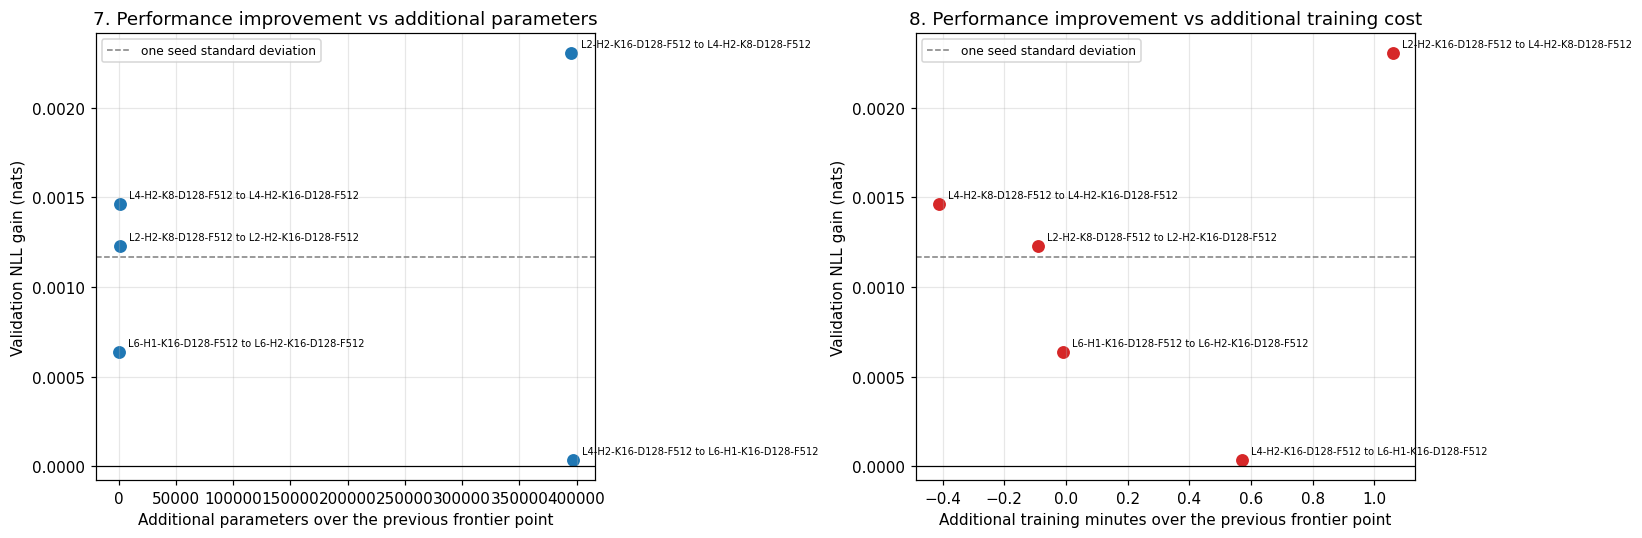

Frontier steps whose NLL gain is smaller than one seed standard deviation: 2 of 5
               from                  to  extra_parameters  nll_gain  gain_in_seed_noise_units
L4-H2-K16-D128-F512 L6-H1-K16-D128-F512            396544    0.0000                    0.0302
L6-H1-K16-D128-F512 L6-H2-K16-D128-F512                 0    0.0006                    0.5461


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.0))

axes[0].scatter(marginal["extra_parameters"], marginal["nll_gain"], s=55, color="tab:blue")
for _, row in marginal.iterrows():
    axes[0].annotate(f"{row['from']} to {row['to']}", (row["extra_parameters"], row["nll_gain"]),
                     textcoords="offset points", xytext=(6, 4), fontsize=6.5)
axes[0].set_xlabel("Additional parameters over the previous frontier point")
axes[0].set_ylabel("Validation NLL gain (nats)")
axes[0].set_title("7. Performance improvement vs additional parameters")

axes[1].scatter(marginal["extra_minutes"], marginal["nll_gain"], s=55, color="tab:red")
for _, row in marginal.iterrows():
    axes[1].annotate(f"{row['from']} to {row['to']}", (row["extra_minutes"], row["nll_gain"]),
                     textcoords="offset points", xytext=(6, 4), fontsize=6.5)
axes[1].set_xlabel("Additional training minutes over the previous frontier point")
axes[1].set_ylabel("Validation NLL gain (nats)")
axes[1].set_title("8. Performance improvement vs additional training cost")

for ax in axes:
    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.axhline(SEED_NOISE, color="tab:grey", linestyle="--", linewidth=1.0,
               label="one seed standard deviation")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_marginal_returns.png", bbox_inches="tight")
plt.show()

below_noise = marginal[marginal["nll_gain"] < SEED_NOISE]
print(f"Frontier steps whose NLL gain is smaller than one seed standard deviation: "
      f"{len(below_noise)} of {len(marginal)}")
if len(below_noise):
    print(below_noise[["from", "to", "extra_parameters", "nll_gain", "gain_in_seed_noise_units"]].round(4).to_string(index=False))

**What are we looking at?** Each point is one frontier step. Horizontal axis: what the step cost — extra parameters (left) or extra training minutes (right). Vertical axis: the validation NLL gained. The dashed line marks one median seed SD (0.0012).

**RESULT.** 2 of the 5 steps gain less than one seed SD, and both are the last two steps: L4-H2-K16 → L6-H1-K16 (gain 0.0000 for +396,544 parameters) and L6-H1-K16 → L6-H2-K16 (gain 0.0006 with no change in parameter count).

**INTERPRETATION.** The steps up to L4-H2-K16 (0.91M parameters) each gain about one to two seed SDs. The step from 4 to 6 layers gains nothing measurable. This is the pattern expected under diminishing returns, but each point rests on two-seed means, so the individual gains are uncertain.

**What we cannot conclude.** A step below the dashed line bought nothing these runs can distinguish from seed noise; it is not shown to have bought nothing at all.

## 6. Is there a distinct saturation point?

**Question.** Does the frontier have a knee — a size beyond which the improvement per unit of size drops sharply — or does it decline smoothly?

**Test.** Two descriptions of the frontier are fitted to validation NLL against log(parameter count):

* a single straight line;
* a two-segment line that may change slope at one frontier point, with the breakpoint chosen to minimise the residual sum of squares (every interior point is tried).

**Conditions for reporting a breakpoint** (both required, both stated in measured quantities):

1. the residual SD of the two-segment fit must be below the median seed SD, so that what is left unexplained is no larger than seed noise;
2. the slope after the breakpoint must be at least ten times shallower than the slope before it, so that the change is a flattening rather than a mild bend.

The factor of ten in condition 2 is a **PROVISIONAL** convention adopted for this analysis; it has no theoretical basis. The fitted slopes are saved, so the result can be recomputed under another convention without retraining anything. If either condition fails, the notebook reports that the experiment gives no evidence for a distinct saturation point and reports no breakpoint. With fewer than five frontier points, no fit is attempted.

In [ ]:
def straight_line_fit(x, y):
    slope, intercept = np.polyfit(x, y, 1)
    residual = y - (slope * x + intercept)
    return {"slope": float(slope), "intercept": float(intercept),
            "rss": float((residual ** 2).sum()),
            "residual_sd": float(residual.std(ddof=1)) if len(residual) > 2 else float("nan")}


def two_segment_fit(x, y):
    # Try every interior point as the breakpoint; keep the one with the smallest residual sum of squares.
    best = None
    for break_position in range(2, len(x) - 1):
        left = straight_line_fit(x[:break_position + 1], y[:break_position + 1])
        right = straight_line_fit(x[break_position:], y[break_position:])
        rss = left["rss"] + right["rss"]
        if best is None or rss < best["rss"]:
            residual_count = len(x)
            best = {"break_position": break_position, "rss": float(rss),
                    "slope_before": left["slope"], "slope_after": right["slope"],
                    "residual_sd": float(np.sqrt(rss / max(1, residual_count - 4)))}
    return best


log_parameters = np.log(frontier["parameters"].to_numpy().astype(float))
frontier_nll = frontier["val_nll"].to_numpy()

if len(frontier) < 5:
    elbow_report = {"enough_frontier_points": False, "n_frontier_points": int(len(frontier)),
                    "conclusion": "Fewer than five points lie on the frontier. A breakpoint cannot be "
                                  "distinguished from a straight line with this many points, so the "
                                  "experiment does not provide evidence for a distinct saturation point."}
else:
    single = straight_line_fit(log_parameters, frontier_nll)
    segmented = two_segment_fit(log_parameters, frontier_nll)
    slope_ratio = (abs(segmented["slope_before"]) / abs(segmented["slope_after"])
                   if segmented["slope_after"] != 0 else float("inf"))
    residual_condition = segmented["residual_sd"] < SEED_NOISE
    slope_condition = slope_ratio >= 10.0
    elbow_report = {
        "enough_frontier_points": True,
        "n_frontier_points": int(len(frontier)),
        "seed_noise_reference": SEED_NOISE,
        "single_line_slope_per_log_parameter": single["slope"],
        "single_line_residual_sd": single["residual_sd"],
        "two_segment_residual_sd": segmented["residual_sd"],
        "slope_before_break": segmented["slope_before"],
        "slope_after_break": segmented["slope_after"],
        "slope_ratio": float(slope_ratio),
        "breakpoint_architecture": str(frontier.iloc[segmented["break_position"]]["architecture"]),
        "breakpoint_parameters": int(frontier.iloc[segmented["break_position"]]["parameters"]),
        "residual_condition_met": bool(residual_condition),
        "slope_condition_met": bool(slope_condition),
        "slope_ratio_threshold": 10.0,
        "slope_ratio_threshold_origin": "provisional convention adopted in notebook 10; no theoretical basis",
    }
    elbow_report["saturation_point_supported"] = bool(residual_condition and slope_condition)

training.save_json(RESULTS_DIR / "10_elbow_report.json", elbow_report)
print(json.dumps(elbow_report, indent=2))

{
  "enough_frontier_points": true,
  "n_frontier_points": 6,
  "seed_noise_reference": 0.0011670040884182626,
  "single_line_slope_per_log_parameter": -0.005185287794686928,
  "single_line_residual_sd": 0.0007395177229215237,
  "two_segment_residual_sd": 0.0009986683980647102,
  "slope_before_break": -0.0063803776474454605,
  "slope_after_break": -0.0009793797900470495,
  "slope_ratio": 6.514712384598978,
  "breakpoint_architecture": "L4-H2-K16-D128-F512",
  "breakpoint_parameters": 911119,
  "residual_condition_met": true,
  "slope_condition_met": false,
  "slope_ratio_threshold": 10.0,
  "slope_ratio_threshold_origin": "provisional convention adopted in notebook 10; no theoretical basis",
  "saturation_point_supported": false
}


/tmp/ipykernel_730/4215811154.py:2: RankWarning: Polyfit may be poorly conditioned
  slope, intercept = np.polyfit(x, y, 1)


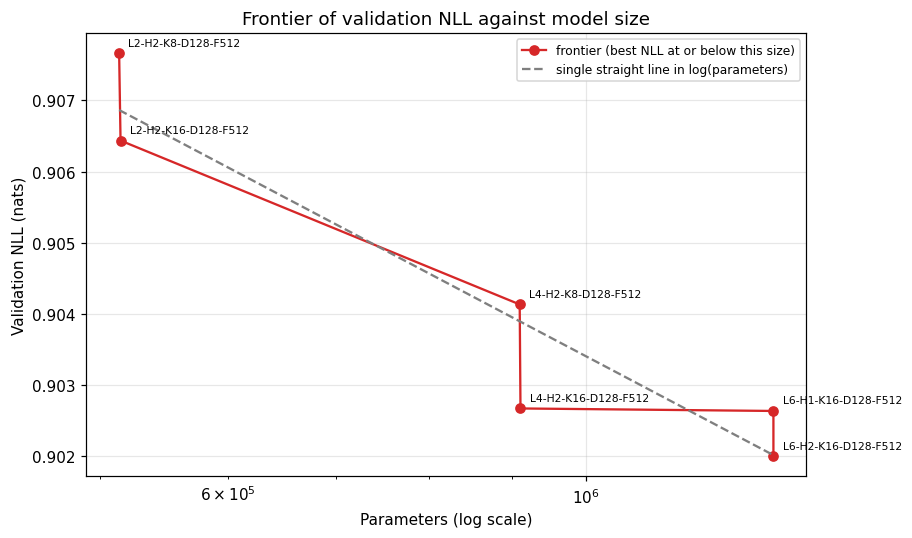

No distinct saturation point is reported: the slope ratio across the best breakpoint is 6.51, below the provisional factor of 10.


In [ ]:
fig, ax = plt.subplots(figsize=(8.4, 5.0))
ax.plot(frontier["parameters"], frontier["val_nll"], marker="o", color="tab:red",
        label="frontier (best NLL at or below this size)")
for _, row in frontier.iterrows():
    ax.annotate(row["architecture"], (row["parameters"], row["val_nll"]),
                textcoords="offset points", xytext=(6, 5), fontsize=7)
if elbow_report.get("enough_frontier_points"):
    fitted = np.polyval([elbow_report["single_line_slope_per_log_parameter"],
                         frontier_nll.mean() - elbow_report["single_line_slope_per_log_parameter"] * log_parameters.mean()],
                        log_parameters)
    ax.plot(frontier["parameters"], fitted, linestyle="--", color="tab:grey",
            label="single straight line in log(parameters)")
    if elbow_report["saturation_point_supported"]:
        ax.axvline(elbow_report["breakpoint_parameters"], color="tab:blue", linestyle=":",
                   label=f"breakpoint: {elbow_report['breakpoint_architecture']}")
ax.set_xscale("log")
ax.set_xlabel("Parameters (log scale)")
ax.set_ylabel("Validation NLL (nats)")
ax.set_title("Frontier of validation NLL against model size")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_frontier_and_fit.png", bbox_inches="tight")
plt.show()

if not elbow_report.get("enough_frontier_points"):
    print(elbow_report["conclusion"])
elif elbow_report["saturation_point_supported"]:
    print(f"A breakpoint is supported at {elbow_report['breakpoint_architecture']} "
          f"({elbow_report['breakpoint_parameters']:,} parameters). "
          f"Slope before: {elbow_report['slope_before_break']:.4f} nats per log-parameter; "
          f"after: {elbow_report['slope_after_break']:.4f}.")
else:
    reasons = []
    if not elbow_report["residual_condition_met"]:
        reasons.append(f"the two-segment fit leaves a residual spread of "
                       f"{elbow_report['two_segment_residual_sd']:.4f} nats, which is not below the "
                       f"seed noise of {SEED_NOISE:.4f}")
    if not elbow_report["slope_condition_met"]:
        reasons.append(f"the slope ratio across the best breakpoint is "
                       f"{elbow_report['slope_ratio']:.2f}, below the provisional factor of 10")
    print("No distinct saturation point is reported: " + "; ".join(reasons) + ".")

**What are we looking at?** The frontier (red) with the single straight-line fit in log(parameter count) drawn over it (grey dashed). A vertical breakpoint line would appear only if both conditions held; it does not appear.

**RESULT.** Six frontier points. Best breakpoint: L4-H2-K16 (911,119 parameters). Slope before −0.0064 and after −0.0010 nats per unit log(parameters): a ratio of 6.51, below the factor of 10, so condition 2 fails. Condition 1 holds (two-segment residual SD 0.0010 against a median seed SD of 0.0012). **No saturation point is supported.**

**OBSERVATION.** The single straight line already leaves a residual SD of 0.0007, lower than the two-segment fit's 0.0010 (which is computed with four fitted parameters). NumPy also warns that a line fit may be poorly conditioned; the frontier contains two points with the same parameter count (L6-H1-K16 and L6-H2-K16, 1,307,663).

**INTERPRETATION.** The frontier bends at about 0.9M parameters (slope ratio 6.51), but the bend does not meet the pre-stated condition for a distinct knee. Under this analysis the frontier is described as a steady decline over the range tested rather than a curve with a knee.

**What we cannot conclude.** A frontier of six two-seed points cannot distinguish a gradual bend from a sharp one with much confidence. The absence of a supported breakpoint is not evidence that returns continue; the last two frontier steps were below seed noise (Section 5).

## 7. The "2 → 4 → 6 → 8 layers" pattern, checked against the measurements

The motivating example for this analysis was a pattern of the form: going from two to four layers gives a substantial improvement, four to six a smaller one, six to eight almost none. The table extracts that comparison from the measurements, at each context length separately, so the pattern is checked rather than assumed. Gains are also given in median-seed-SD units.

**Note on K = 16.** The K = 16 series contains the head-count and d_ff variants at 6 layers as well as the 2-head depth series, so its rows include "6L to 6L" steps between variants and its "4L to 6L" step compares L4-H2 with L6-H1. Only the 2L → 4L step and the 6L → 8L step at K = 16 are depth steps between 2-head base-width models.

**RESULT.**

* **2L → 4L:** gain at K = 8, 16 and 32 (0.0035, 0.0038, 0.0044 nats; 3.0–3.8 seed SDs); a loss at K = 64 (−0.0050).
* **4L → 6L:** no gain at K = 8 or K = 16 (both about 0.0000); a loss at K = 32 (−0.0044) and a gain at K = 64 (+0.0050).
* **6L → 8L:** a loss at K = 8 (−0.0014), a gain at K = 16 (+0.0018, measured from the last 6-layer variant in the series) and K = 32 (+0.0032), a loss at K = 64 (−0.0025).

In [ ]:
depth_steps = []
for context_length in sorted(capacity_summary["context_length"].unique()):
    line = capacity_summary[(capacity_summary["context_length"] == context_length)
                            & (capacity_summary["d_model"] == BASE_D_MODEL)].sort_values("n_layers")
    for position in range(1, len(line)):
        previous = line.iloc[position - 1]
        current = line.iloc[position]
        depth_steps.append({
            "context_length": int(context_length),
            "step": f"{int(previous['n_layers'])}L to {int(current['n_layers'])}L",
            "nll_before": previous["val_nll"], "nll_after": current["val_nll"],
            "nll_gain": previous["val_nll"] - current["val_nll"],
            "gain_in_seed_noise_units": (previous["val_nll"] - current["val_nll"]) / SEED_NOISE
                if SEED_NOISE > 0 else np.nan,
            "extra_parameters": int(current["parameters"] - previous["parameters"]),
            "extra_minutes": (current["runtime_seconds"] - previous["runtime_seconds"]) / 60,
        })
depth_step_table = pd.DataFrame(depth_steps)
depth_step_table.to_csv(RESULTS_DIR / "10_depth_steps.csv", index=False)
depth_step_table.round(4)

,context_length,step,nll_before,nll_after,nll_gain,gain_in_seed_noise_units,extra_parameters,extra_minutes
0,8,2L to 4L,0.9077,0.9041,0.0035,3.0221,396544,0.9672
1,8,4L to 6L,0.9041,0.9042,-0.0000,-0.0378,396544,0.7779
2,8,6L to 8L,0.9042,0.9056,-0.0014,-1.1923,396544,0.5709
3,16,2L to 4L,0.9064,0.9027,0.0038,3.2239,396544,0.6460
4,16,4L to 6L,0.9027,0.9026,0.0000,0.0302,396544,0.5718
5,16,6L to 6L,0.9026,0.9020,0.0006,0.5461,0,-0.0096
6,16,6L to 6L,0.9020,0.9032,-0.0012,-1.0257,789504,0.5628
7,16,6L to 6L,0.9032,0.9030,0.0002,0.1807,-789504,-0.4866
8,16,6L to 6L,0.9030,0.9042,-0.0012,-1.0667,0,0.0158
9,16,6L to 8L,0.9042,0.9024,0.0018,1.5551,396544,0.7584


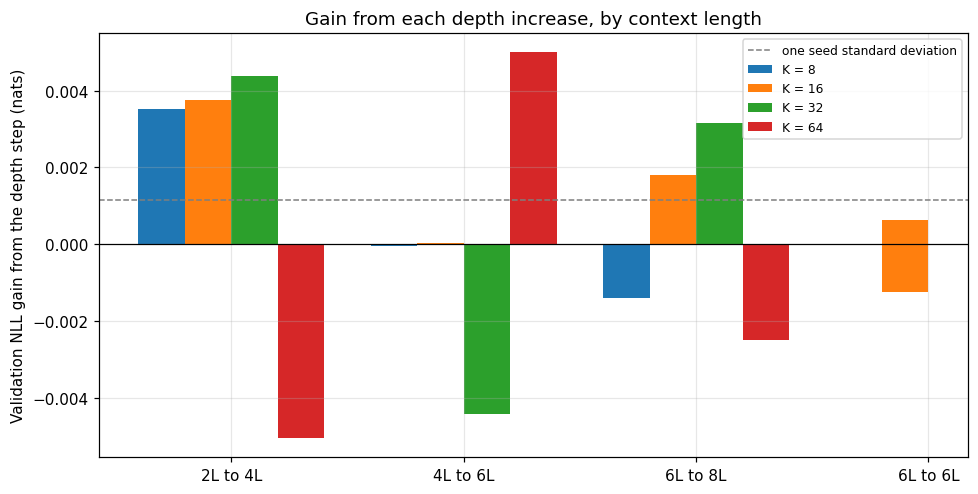

In [ ]:
fig, ax = plt.subplots(figsize=(9.0, 4.6))
step_order = list(dict.fromkeys(depth_step_table["step"]))
width = 0.8 / max(1, len(depth_step_table["context_length"].unique()))
for position, context_length in enumerate(sorted(depth_step_table["context_length"].unique())):
    subset = depth_step_table[depth_step_table["context_length"] == context_length]
    offsets = np.array([step_order.index(step) for step in subset["step"]]) + position * width
    ax.bar(offsets, subset["nll_gain"], width=width, label=f"K = {context_length}")
ax.axhline(0.0, color="black", linewidth=0.8)
ax.axhline(SEED_NOISE, color="tab:grey", linestyle="--", linewidth=1.0, label="one seed standard deviation")
ax.set_xticks(np.arange(len(step_order)) + 0.4 - width / 2)
ax.set_xticklabels(step_order)
ax.set_ylabel("Validation NLL gain from the depth step (nats)")
ax.set_title("Gain from each depth increase, by context length")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_depth_step_gains.png", bbox_inches="tight")
plt.show()

**What are we looking at?** One bar per depth step per context length: the validation NLL gained by adding those layers (positive = improvement). The dashed line is one median seed SD.

**INTERPRETATION.** The first part of the expected pattern is reproduced at K = 8, 16 and 32: 2 → 4 layers gives a gain of three to four seed SDs. The rest is not: beyond 4 layers the steps do not shrink steadily towards zero but change sign from one context length to the next. At K = 32 and K = 64 consecutive steps alternate between gains and losses of 2–4 seed SDs, which is not the monotone pattern the example describes.

**What we cannot conclude.** Bars shorter than the dashed line, in either direction, support no statement about that step. Negative bars (the deeper model was worse on validation) are possible on held-out data and are not measurement errors. With two seeds, none of these steps has been tested under the decision rule.

In [ ]:
summary = {
    "configurations_analysed": int(len(capacity_summary)),
    "frontier_points": int(len(frontier)),
    "seed_noise_reference_nats": SEED_NOISE,
    "best_configuration": str(capacity_summary.iloc[0]["architecture"]),
    "best_val_nll": float(capacity_summary.iloc[0]["val_nll"]),
    "smallest_configuration_within_seed_noise_of_best": str(
        capacity_summary[capacity_summary["val_nll"] <= capacity_summary["val_nll"].min() + SEED_NOISE]
        .sort_values("parameters").iloc[0]["architecture"]),
    "frontier_steps_below_seed_noise": int(len(below_noise)),
    "saturation_point_supported": bool(elbow_report.get("saturation_point_supported", False)),
    "test_split_touched": False,
}
training.save_json(RESULTS_DIR / "10_summary.json", summary)
print(json.dumps(summary, indent=2))

{
  "configurations_analysed": 23,
  "frontier_points": 6,
  "seed_noise_reference_nats": 0.0011670040884182626,
  "best_configuration": "L6-H2-K16-D128-F512",
  "best_val_nll": 0.9019999504089355,
  "smallest_configuration_within_seed_noise_of_best": "L4-H2-K16-D128-F512",
  "frontier_steps_below_seed_noise": 2,
  "saturation_point_supported": false,
  "test_split_touched": false
}


## 8. Summary

| Item | Result |
|---|---|
| Configurations analysed | 23 (capacity sweep, Track A training setting) |
| Reference scale (median seed SD) | 0.0012 nats |
| Frontier | 6 points, L2-H2-K8 (0.9077) to L6-H2-K16 (0.9020) |
| Largest axis effect | context length (range 0.0264); layers 0.0044; heads 0.0022 |
| Frontier steps below one seed SD | 2 of 5 (both beyond L4-H2-K16) |
| Saturation point | not supported (slope ratio 6.51 < 10) |
| Lowest mean validation NLL | L6-H2-K16-D128-F512, 0.9020 |
| Smallest configuration within one seed SD of it | L4-H2-K16-D128-F512 (descriptive) |
| Test split | not accessed; no training performed |

**What this establishes.** In this sweep, the useful capacity effects are K = 16 against longer windows, and 2 → 4 layers. Beyond about 0.9M parameters (4 layers) the frontier gains fall below one seed SD, but the bend is not sharp enough to meet the pre-stated condition for a distinct saturation point.

**What it does not establish.** "Smallest configuration within one seed SD of the best" is a descriptive quantity based on two screening seeds; it is not a comparison under the decision rule. That comparison needs more seeds and the match-level bootstrap, and is made separately for the shortlisted architectures at the tuned training setting.

The frontier (`results/10_frontier.csv`), the marginal returns (`results/10_marginal_returns.csv`) and the saturation report (`results/10_elbow_report.json`) are saved for the experiment summary.